# COGS 109 Checkpoint 2 | Member 3: Ishaan Tibdewal | Lasso logistic regression
**Question:** Which pre-draft measurements predict whether a player scores above the median NBA PPG (5.65) in their first three post-combine seasons?

**My method:** Lasso logistic regression. Thomas Ton uses forward stepwise selection and Riley Ramos uses elastic net logistic regression.

Everyone uses the same data, train/test split, binary outcome, 5 CV folds and 24 candidate predictors. Only the selection method is different.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs('reports', exist_ok=True)

## Step 1: Load the data and make the binary outcome

In [2]:
features = pd.read_csv('../data/predraft_features.csv')
outcomes = pd.read_csv('../data/nba_outcomes.csv')

# same sample as Checkpoint 1: players matched to NCAA stats
df = features.merge(outcomes[['player_id', 'ppg_3yr']], on='player_id')
df = df[df.ncaa_match_status == 'matched'].reset_index(drop=True)
print('n =', len(df))

n = 770


In [3]:
# same 80/20 split as Checkpoint 1
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=42,
                                       stratify=df.position_group)
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
print('Train:', len(train), '| Test:', len(test))

Train: 616 | Test: 154


No natural cutoff exists for NBA PPG, so we use the training median. This splits the classes 50/50.

In [4]:
# 1 = scored more than the training median, 0 = at or below it
threshold = train.ppg_3yr.median()
y_train = (train.ppg_3yr > threshold).astype(int).values
y_test = (test.ppg_3yr > threshold).astype(int).values

print('Threshold:', round(threshold, 2), 'PPG')
print('Proportion of 1s in train:', round(y_train.mean(), 3))
print('Proportion of 1s in test:', round(y_test.mean(), 3))

Threshold: 5.65 PPG
Proportion of 1s in train: 0.5
Proportion of 1s in test: 0.5


## Step 2: Candidate predictors and CV folds
- 10 combine measurements and 11 NCAA stats (quantitative).
- `skipped_drills`: 1 if the player has no agility, sprint or vertical result. Top prospects often skip the drills, so filling those blanks with the median would hide this.
- Position: 2 dummies, baseline Guard.
- That is 24 predictors with n = 616 training players. IDs, names, team and years are left out.
- CV error = proportion of validation players misclassified (0.5 cutoff), averaged over 5 folds.

In [5]:
combine = ['height_in', 'weight_lb', 'wingspan_in', 'standing_reach_in', 'vertical_max_in',
           'vertical_standing_in', 'sprint_sec', 'agility_sec', 'bench_reps', 'body_fat_pct']
ncaa = ['ncaa_games', 'ncaa_mpg', 'ncaa_ppg', 'ncaa_apg', 'ncaa_rpg', 'ncaa_spg', 'ncaa_bpg',
        'ncaa_tov_pg', 'ncaa_fg_pct', 'ncaa_3p_pct', 'ncaa_ft_pct']

for d in [train, test]:
    # position dummies (baseline = Guard)
    d['pos_Forward'] = (d.position_group == 'Forward').astype(int)
    d['pos_Center'] = (d.position_group == 'Center').astype(int)
    # 1 = skipped the athletic drills (no agility, sprint or vertical result)
    drills = d[['agility_sec', 'sprint_sec', 'vertical_max_in']]
    d['skipped_drills'] = drills.isna().all(axis=1).astype(int)

predictors = combine + ncaa + ['skipped_drills', 'pos_Forward', 'pos_Center']
print('Number of predictors:', len(predictors))

# fill missing values with the TRAINING median (never look at the test set)
X_train = train[predictors].reset_index(drop=True)
X_test = test[predictors].reset_index(drop=True)
for col in predictors:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

skipped = X_train.skipped_drills == 1
print('Proportion of 1s | skipped drills:', round(y_train[skipped].mean(), 2),
      '| did drills:', round(y_train[~skipped].mean(), 2))

Number of predictors: 24
Proportion of 1s | skipped drills: 0.65 | did drills: 0.47


In [6]:
# 5 folds of the training set, the same for everyone
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))


def cv_error(model, cols):
    # misclassification rate on each validation fold, then the average and its standard error
    errors = []
    for fit_idx, val_idx in folds:
        model.fit(X_train.loc[fit_idx, cols], y_train[fit_idx])
        pred = model.predict(X_train.loc[val_idx, cols])
        errors.append(np.mean(pred != y_train[val_idx]))
    return np.mean(errors), np.std(errors, ddof=1) / np.sqrt(len(errors))


def fit_logit(cols):
    # ordinary logistic regression on the whole training set (gives AIC, BIC, p-values)
    X = sm.add_constant(X_train[cols], has_constant='add')
    return sm.Logit(y_train, X).fit(disp=0)


# plain logistic regression for CV (scaling only helps the solver, predictions are the same)
plain_logistic = make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=5000))

## Step 3: Lasso
Lasso shrinks coefficients, and a big enough λ sets some of them to exactly 0. Predictors are standardized so the penalty treats them equally.

I use the **1-SE rule**: the biggest λ whose CV error is within one standard error of the lowest. The lowest-CV λ keeps almost every predictor (about the same model as elastic net), while the 1-SE rule gives a much simpler model that is about as accurate.

In [7]:
lambdas = np.logspace(-1, 2, 40)   # penalty strength λ (sklearn uses C = 1/λ)

grid = []
for lam in lambdas:
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(penalty='l1', C=1 / lam, solver='saga', max_iter=20000))
    err, se = cv_error(model, predictors)
    model.fit(X_train, y_train)
    coefs = model[-1].coef_[0]   # [-1] is the logistic regression step of the pipeline
    grid.append({'lambda': lam, 'cv_error': err, 'se': se,
                 'n_kept': np.sum(coefs != 0), 'coefs': coefs})

grid = pd.DataFrame(grid)
print(grid[['lambda', 'cv_error', 'se', 'n_kept']].round(3).to_string(index=False))

 lambda  cv_error    se  n_kept
  0.100     0.432 0.026      24
  0.119     0.432 0.026      24
  0.143     0.432 0.026      24
  0.170     0.433 0.026      24
  0.203     0.433 0.026      24
  0.242     0.433 0.026      23
  0.289     0.433 0.025      23
  0.346     0.433 0.025      23
  0.412     0.435 0.024      23
  0.492     0.433 0.024      23
  0.588     0.435 0.024      23
  0.702     0.429 0.024      23
  0.838     0.430 0.024      23
  1.000     0.427 0.024      23
  1.194     0.433 0.022      22
  1.425     0.433 0.022      22
  1.701     0.433 0.024      22
  2.031     0.440 0.024      21
  2.424     0.435 0.026      20
  2.894     0.448 0.024      20
  3.455     0.446 0.021      19
  4.125     0.450 0.019      19
  4.924     0.455 0.014      17
  5.878     0.453 0.013      15
  7.017     0.446 0.015      13
  8.377     0.451 0.016      12
 10.000     0.455 0.016      11
 11.938     0.463 0.015       9
 14.251     0.455 0.017       7
 17.013     0.450 0.020       5
 20.309 

In [8]:
# 1-SE rule: the biggest λ whose CV error is within 1 standard error of the lowest
lowest = grid.loc[grid.cv_error.idxmin()]
cutoff = lowest.cv_error + lowest.se
best = grid[grid.cv_error <= cutoff].iloc[-1]   # rows go from small to big λ
final_predictors = [var for var, c in zip(predictors, best.coefs) if c != 0]

print('Lowest CV error:', round(lowest.cv_error, 3), 'with', lowest.n_kept, 'predictors')
print('1-SE cutoff:', round(cutoff, 3))
print('Chosen λ =', round(best['lambda'], 3), '| CV error =', round(best.cv_error, 3))
print('Kept', len(final_predictors), 'of', len(predictors), 'predictors:', final_predictors)

Lowest CV error: 0.427 with 23 predictors
1-SE cutoff: 0.451
Chosen λ = 28.943 | CV error = 0.45
Kept 3 of 24 predictors: ['agility_sec', 'ncaa_ppg', 'skipped_drills']


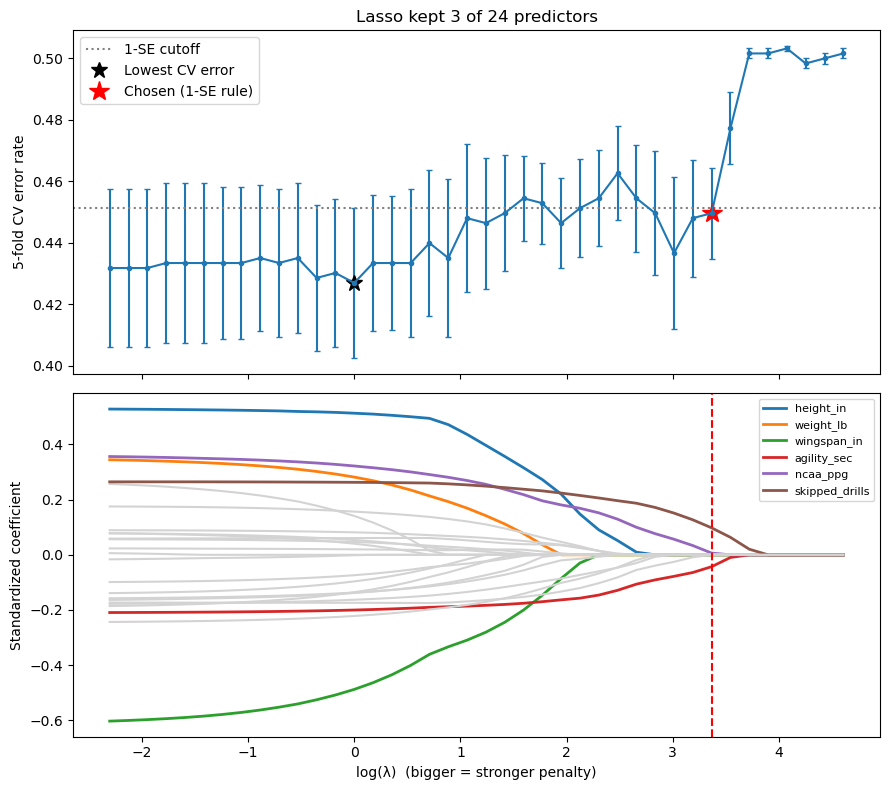

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

axs[0].errorbar(np.log(grid['lambda']), grid.cv_error, yerr=grid.se, marker='o', markersize=3, capsize=2)
axs[0].axhline(cutoff, color='grey', linestyle=':', label='1-SE cutoff')
axs[0].plot(np.log(lowest['lambda']), lowest.cv_error, 'k*', markersize=12, label='Lowest CV error')
axs[0].plot(np.log(best['lambda']), best.cv_error, 'r*', markersize=15, label='Chosen (1-SE rule)')
axs[0].set(ylabel='5-fold CV error rate',
           title=f'Lasso kept {len(final_predictors)} of {len(predictors)} predictors')
axs[0].legend()

# coefficient paths; the 5 biggest coefficients at the lowest-CV λ are labeled
paths = np.array(grid.coefs.tolist())
top5 = np.argsort(-np.abs(lowest.coefs))[:5]
for i, var in enumerate(predictors):
    if i in top5 or var in final_predictors:
        axs[1].plot(np.log(grid['lambda']), paths[:, i], linewidth=2, label=var)
    else:
        axs[1].plot(np.log(grid['lambda']), paths[:, i], color='lightgrey')
axs[1].axvline(np.log(best['lambda']), color='red', linestyle='--')
axs[1].set(xlabel='log(λ)  (bigger = stronger penalty)', ylabel='Standardized coefficient')
axs[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('reports/lasso_cv_plot.png', dpi=150)
plt.show()

**TODO (Ishaan):** How many predictors did lasso keep? Are they combine or NCAA stats?

## Step 4: Selected model
For lasso and elastic net, the kept predictors are refit as an ordinary logistic regression. Odds ratio = e^β: how the odds of being an above-median scorer change for a 1-unit increase in a predictor, holding the others fixed.

In [10]:
final = fit_logit(final_predictors)
cv, se = cv_error(plain_logistic, final_predictors)

print('Predictors:', len(final_predictors))
print('AIC:', round(final.aic, 1))
print('BIC:', round(final.bic, 1))
print('CV error rate:', round(cv, 3))

Predictors: 3
AIC: 836.7
BIC: 854.4
CV error rate: 0.429


In [11]:
table = pd.DataFrame({'coef': final.params,
                      'odds_ratio': np.exp(final.params),
                      'p_value': final.pvalues})
# standardized coefficient = change in log-odds for a 1 SD increase (lets us compare predictors)
table['std_coef'] = table.coef * X_train[final_predictors].std()
table = table.sort_values('std_coef', key=abs, ascending=False)
print(table.round(3))

                 coef  odds_ratio  p_value  std_coef
skipped_drills  0.749       2.115    0.001     0.287
agility_sec    -0.426       0.653    0.016    -0.204
ncaa_ppg        0.047       1.048    0.030     0.182
const           3.954      52.158    0.055       NaN


In [12]:
b = final.params
equation = 'log(p / (1 - p)) = ' + str(round(b['const'], 3))
for var in final_predictors:
    coef = round(b[var], 3)
    if coef >= 0:
        equation += f' + {coef}*{var}'
    else:
        equation += f' - {abs(coef)}*{var}'

print(f'p = P(NBA PPG > {threshold:.2f})')
print(equation)

p = P(NBA PPG > 5.65)
log(p / (1 - p)) = 3.954 - 0.426*agility_sec + 0.047*ncaa_ppg + 0.749*skipped_drills


**TODO (Ishaan):** Interpret at least two odds ratios. Example: "each extra college point per game multiplies the odds of being an above-median NBA scorer by 1.07 (7% higher odds)". For position, name the baseline (Guard).

## Step 5: Test the model once
Predict 1 if the probability is above 0.5. The baseline always predicts the most common training class.

In [13]:
X_test_const = sm.add_constant(X_test[final_predictors], has_constant='add')
prob = final.predict(X_test_const)
pred = (prob > 0.5).astype(int)

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
auc = roc_auc_score(y_test, prob)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

# baseline: always predict the most common class in the training set
majority = 1 if y_train.mean() >= 0.5 else 0
baseline = np.mean(y_test == majority)

print('Test accuracy:', round(accuracy, 3), '| baseline:', round(baseline, 3))
print('Precision:', round(precision, 3), '| Recall:', round(recall, 3), '| AUC:', round(auc, 3))
print('TP:', tp, '| FP:', fp, '| TN:', tn, '| FN:', fn)

Test accuracy: 0.623 | baseline: 0.5
Precision: 0.651 | Recall: 0.532 | AUC: 0.659
TP: 41 | FP: 22 | TN: 55 | FN: 36


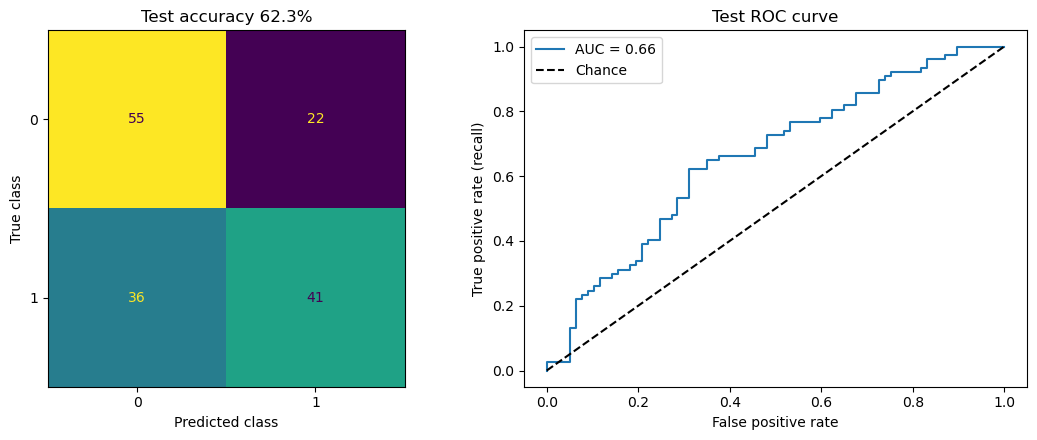

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axs[0], colorbar=False)
axs[0].set(xlabel='Predicted class', ylabel='True class', title=f'Test accuracy {accuracy:.1%}')

fpr, tpr, _ = roc_curve(y_test, prob)
axs[1].plot(fpr, tpr, label=f'AUC = {auc:.2f}')
axs[1].plot([0, 1], [0, 1], 'k--', label='Chance')
axs[1].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='Test ROC curve')
axs[1].legend()

plt.tight_layout()
plt.savefig('reports/lasso_test.png', dpi=150)
plt.show()

**TODO (Ishaan):** Interpret the AUC in one sentence: "for a random above-median and below-median scorer, the model gives the above-median scorer the higher probability X% of the time." Does the model beat the baseline?

In [15]:
# save results for the group comparison notebook
results = pd.DataFrame([{'member': 'Ishaan Tibdewal', 'method': 'Lasso logistic regression',
                         'n_predictors': len(final_predictors), 'predictors': ', '.join(final_predictors),
                         'cv_error': cv, 'aic': final.aic, 'bic': final.bic,
                         'accuracy': accuracy, 'auc': auc, 'precision': precision, 'recall': recall,
                         'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn, 'baseline': baseline}])
results.to_csv('reports/lasso_results.csv', index=False)
pd.DataFrame({'fpr': fpr, 'tpr': tpr}).to_csv('reports/lasso_roc.csv', index=False)

## Conclusion

**TODO (Ishaan):** 3-4 bullets: predictors kept, AIC/BIC/CV error, test accuracy vs baseline, AUC.